# PYTORCH


Strojno učenje je spreminjanje podtakov v števike, in iskanje vzorcev v teh številkah.

Globoko učenje se uporablja, ko govorimo o nestrukturiranih podatkih.



In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)
from torch import nn
from pathlib import Path



2.14.1+cu130


## Tensor

- osnovna oblika torcha je tensor (neke vrste multi dimenziniran array)

- Ima lahko n-število dimenzij:

    - skalar (številka): 0 dimenzij
    - vektor [1, 2, 3]: 1 dimenzija
    - matrika (višina, širina): 2 dimenziji
    - 3D tensor (npr. barvna slika (višina, širina, globina)): 3 dimenzije 
    - ...

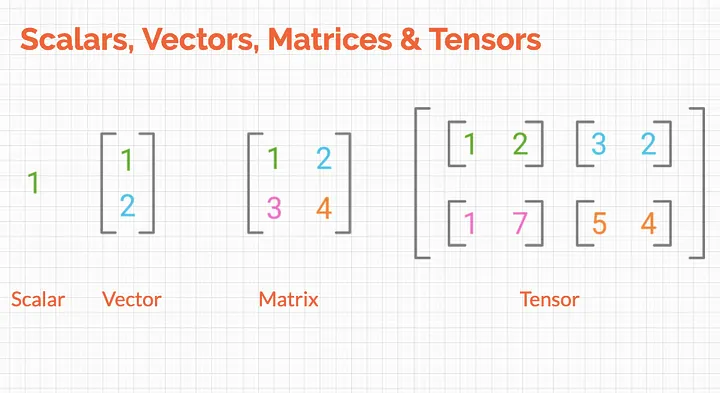


Naredi se ga lahko:

- iz podatkov z `torch.tensor(podatki)`

- iz poljubne oblike `torch.ones/zeros/randn(oblika)`

- oponašanje že obstoječega tensorja `torch.rand_like(podatki, dtype=torch.float)`


Trije atributi tensorja so:

- oblika (vrstice in stolpci)
- podatkovni tip (najpogosteje **float32**, ker je se da minimalno spreminjati vrednosti, za razlike od int)
- naprava (cpu/gpu)


In [2]:
podatki =[[1,2,3],
          [4,5,6]]

moj_tensor=torch.tensor(podatki, dtype=torch.float32)

print(moj_tensor)

oblika=(2,3)

random=torch.randn(oblika)

print(random)
print()

rand_kot_podatki= torch.rand_like(moj_tensor,dtype=torch.float) 

print(rand_kot_podatki) #oblika ista kot moj_tensor, vendar je vsebina drugačna


tensor([[1., 2., 3.],
        [4., 5., 6.]])
tensor([[ 1.3170, -1.9620,  1.1530],
        [-0.7647, -0.1791, -0.2379]])

tensor([[0.7950, 0.2367, 0.3770],
        [0.2417, 0.0397, 0.7716]])


In [3]:
print(f"\nTensor je dimenzije {moj_tensor.ndim}\n") # z ndim lahko hitro preverimo dimenzije 
print(f"Oblika: {moj_tensor.shape}")
print()
print(f"Podatkovni tip: {moj_tensor.dtype}")
print()
print(f"Device: {moj_tensor.device}")


Tensor je dimenzije 2

Oblika: torch.Size([2, 3])

Podatkovni tip: torch.float32

Device: cpu


### 3D tensor

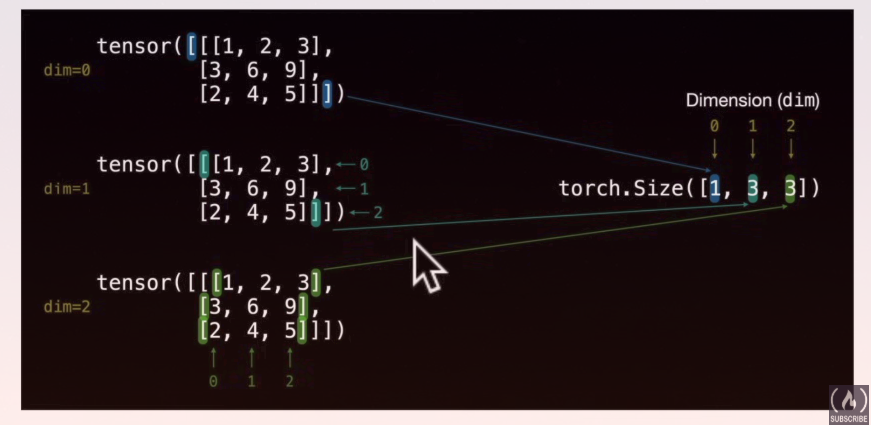

In [4]:
# 3D tensor

tri_D_tensor=torch.tensor([[[1, 2, 3],
                      [4, 5, 6],
                      [8, 9, 10]]])

print(tri_D_tensor.shape)

tri_D_tensor.ndim

torch.Size([1, 3, 3])


3

### `torch.arange`

Za delanje tensorje z dosegom.

In [5]:
torch.arange(start=1, end=999, step=65)

tensor([  1,  66, 131, 196, 261, 326, 391, 456, 521, 586, 651, 716, 781, 846,
        911, 976])

### Pogosti errorji

Trije najpogostrjši errorji so: 

- Tensor ni pravilnega podatkovnega tipa
- Tensor ni pravilne oblike
- Tensor ni na pravi napravi

In [6]:
#Float 32
float_32_tensor=torch.tensor([3.0,6.0,9.0], dtype=torch.float32, #datatype
                             device="cpu", # na kateri napravi je tensorCPU al pa GPU (cuda)
                             requires_grad=False)  #da pytorch sledi gradientu
float_32_tensor.device

device(type='cpu')

## AUTOGRAD

Autograd je PyTorchev sistem za samodejno odvajanje. Med računanjem si zapomni, katere operacije se izvede nad tenzorji, nato pa z verižnim pravilom izračuna gradiente (odvode) glede na vse parametre.

Vklopi se ga z `requires_grad=True`

Brez tega so tensorji zgolj podatki. Z tem pa postanejo učni parametri.

Z `.grad_fn` se gleda, kako je bil tensor narejen (v kateri operaciji).


In [7]:
a=torch.tensor(2.0, requires_grad=True)


## Operacije

### `*` vs `@`

`*` je množenje na podlagi elementov. Torej množi elemnt, ki je na isti poziciji v drugi matriki. Tu morata imeti obe matrii enako obliko. 

`@` je množenje matrik. Ta je pomembnejša. 

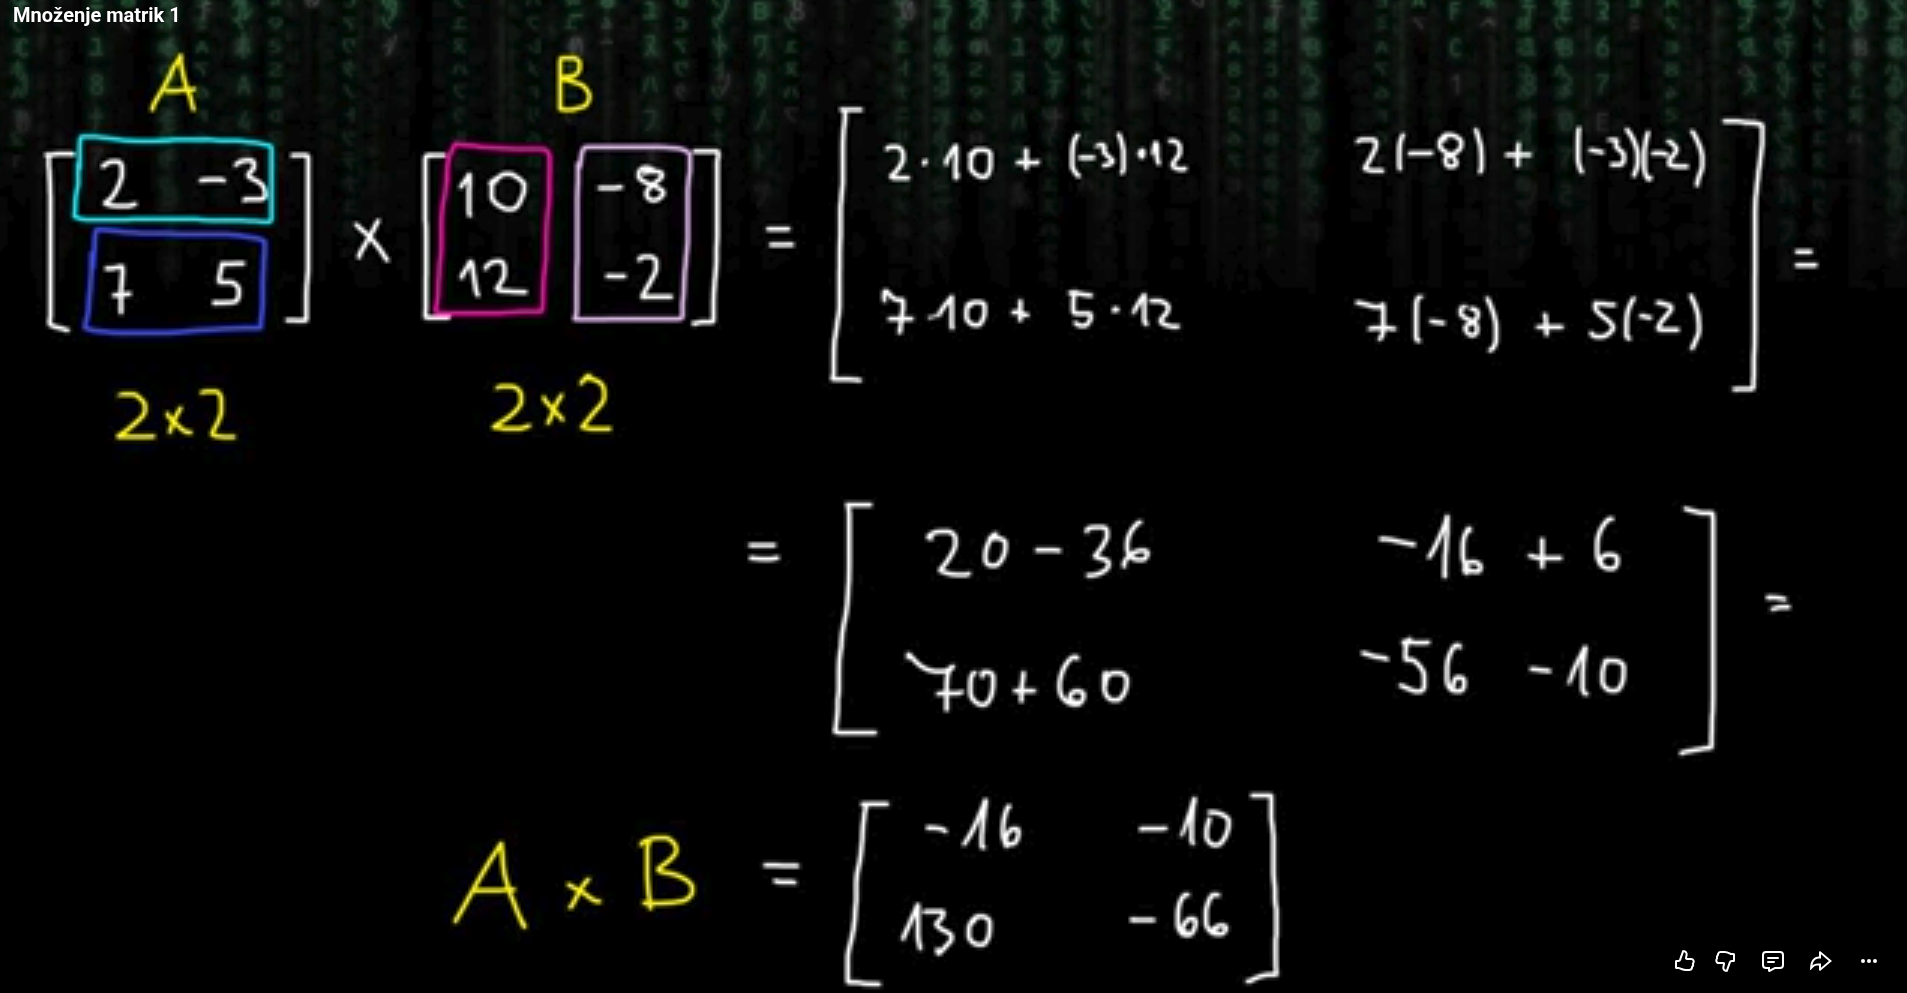 (vir 3)

Pri tem množenju se mora ujemati št. stolpcev prve matrie z številom vrdtic druge matrie. 

Dve pravili za množenje matrik

1.   Notranje dimenzije matrik se morata ujemati
* `(3,2) @ (3,2) ` to ne bi delalo
* `(3,2) @ (2,3) ` to  bi delalo
2.   Matria, ki je rezultat, ima obliko zunanjih dimenzij
* `(3,2) @ (2,3) ` -> `(3,3)`






In [8]:

a=torch.tensor([[1,2],[3,4]])

b=torch.tensor([[10,20],[30,40]])

c= torch.tensor([[10,20,50],[30,40,60]])

print(f"Množenje z *: \n{(a*b)}")
print()
print(f"Monženje z @: \n{a@b}")
print()
print(f"Monženje z @: \n{a@c}")

Množenje z *: 
tensor([[ 10,  40],
        [ 90, 160]])

Monženje z @: 
tensor([[ 70, 100],
        [150, 220]])

Monženje z @: 
tensor([[ 70, 100, 170],
        [150, 220, 390]])


### Errorji oblik

In [9]:
tensor_A=torch.tensor([[1,2],
                       [3,4],
                       [5,6]])

tensor_B=torch.tensor([[7,10],
                       [8,11],
                       [9,12]])


# tensor_A @ tensor_B

# RuntimeError: mat1 and mat2 shapes cannot be multiplied (3x2 and 3x2)

Da bomo popravili ta error bomo tensor_B transpozirali. To pomeni da bomo zamenjali dimenziji tensorja. 

In [10]:
print(tensor_B.T)

tensor_A @ tensor_B.T # ni errorja

tensor([[ 7,  8,  9],
        [10, 11, 12]])


tensor([[ 27,  30,  33],
        [ 61,  68,  75],
        [ 95, 106, 117]])

### Redukcija in `dim`

Redukcija se uporablja za zmanjševanje elemntov tensorja (mean, sum...).

Z `dim` se določi v katero smer se bo redukcija izvedla.

- `dim=0` : vertikalno (stolpci)

- `dim=1` : horizontalno (vrstice)

In [11]:
vrednosti=torch.tensor([[10,20,50],
                        [30,40,60]], dtype=torch.float32)

print(f"Povprečje stolpcev: \n{vrednosti.mean(dim=0)}") # isto bi delovalo z min(), max(), sum()...
print()
print(f"Povprečje vrstic: \n{vrednosti.mean(dim=1)}")

Povprečje stolpcev: 
tensor([20., 30., 55.])

Povprečje vrstic: 
tensor([26.6667, 43.3333])


### Izbira podatkov (indeksiranje)

Deluje na podoben način kot pri numpy z indeksiranjem.

`[:]` pomeni vse elemente v eni dimenziji.

In [12]:
x=torch.arange(12).reshape(3,4)

print(x)

print(f"\n{x[0]}") # prva vrstica

print(f"\n{x[1][2]}") # druga vrstice, tretji elemnt

print(f"\n{x[:,1]}") # drugi stolpec

print(f"\nStolpec 3: \n{x[:,2]}") # v tem primeru : pomeni vse vrstice

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

tensor([0, 1, 2, 3])

6

tensor([1, 5, 9])

Stolpec 3: 
tensor([ 2,  6, 10])


### Argmax in argmin

Uporablja se za iskanje največjih vresnosti. 

In [13]:
print(f"Indeks največje vrednosti v tensorju: {torch.argmax(x)}")
print(f"\nIndeks največje vrednosti v vrsticah: {torch.argmax(x,dim=1)}")

Indeks največje vrednosti v tensorju: 11

Indeks največje vrednosti v vrsticah: tensor([3, 3, 3])


### Reshaping, stacking, squeezing in unsqueezing tensorjev

* Reshaping: preoblikuje tensor v določen shape.
* View:  podobno kot resahping, samo da se memory ohrani. Sprememba drugega tensorja spremeni prvi tensor. 
* Stacking: združi več tensorjev drug na drugega (vstack) oz. drug zdraven drugega (hstack).
* Squeez: odstrani vse `1` dimenzije iz tensorja.
* Unsqueez: doda `1` dimenzije v tensor.
* Permute: vrne view inputa z permutiranimi dimenzijami.

In [14]:
z = torch.arange(1. ,11.)
z, z.shape

(tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]), torch.Size([10]))

In [15]:
# RESHAPE

# z_reshape= z.reshape(1,7)

# RuntimeError: shape '[1, 7]' is invalid for input of size 9

# Oblika mora biti kompatibilna s številom elementov

z_reshape= z.reshape(2,5)

z_reshape,z_reshape.shape

(tensor([[ 1.,  2.,  3.,  4.,  5.],
         [ 6.,  7.,  8.,  9., 10.]]),
 torch.Size([2, 5]))

In [16]:
# STACKED

z_stacked= torch.stack([z,z,z], dim=0)
z_stacked

tensor([[ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.],
        [ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.],
        [ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]])

In [17]:
# Squeez in unsqueez

z_unsqueez = torch.unsqueeze(z, dim=0) # doda 1 dimenzijo

z_squeez = torch.squeeze(z_unsqueez)

z.shape,z_unsqueez.shape,z_squeez.shape

(torch.Size([10]), torch.Size([1, 10]), torch.Size([10]))

In [18]:
# Permute

z_permute = torch.permute(z_reshape, dims=(1,0))

z_reshape, z_permute,

(tensor([[ 1.,  2.,  3.,  4.,  5.],
         [ 6.,  7.,  8.,  9., 10.]]),
 tensor([[ 1.,  6.],
         [ 2.,  7.],
         [ 3.,  8.],
         [ 4.,  9.],
         [ 5., 10.]]))

### torch.gather()

Za iskanje določenih elementov.

In [19]:
podatki=torch.rand_like(x,dtype=torch.float32)
elementi_za_izbor=torch.tensor([[2],[0],[3]]) #indeksi željenih vrednosti

željene_vrednosti=torch.gather(podatki,dim=1, index=elementi_za_izbor) #dim=1 za horizontalen izbor (po vrsticah)

print(podatki)
print()
print(željene_vrednosti) #rezultat so izbrane vrednosti v vsaki vrstici



tensor([[1.3486e-01, 8.4662e-01, 4.8056e-01, 3.0399e-01],
        [4.7505e-04, 3.1879e-02, 6.8137e-01, 2.3270e-01],
        [8.4805e-01, 3.5679e-01, 5.4612e-02, 3.5196e-01]])

tensor([[4.8056e-01],
        [4.7505e-04],
        [3.5196e-01]])


### PyTorch in NumPy

- Podatki v numpy -> PyTorch tensor : `torch.from_numpy(ndarray)`
- PyTorch tensor -> NumPy array : `torch.Tensor.numpy()`


In [20]:
# Iz arraya v tensor

array = np.arange(1.0, 8.0)
tensor_iz_array = torch.from_numpy(array) # trba pazit na dtype (se ohrani): numpy float64, torch float32

array, tensor_iz_array

(array([1., 2., 3., 4., 5., 6., 7.]),
 tensor([1., 2., 3., 4., 5., 6., 7.], dtype=torch.float64))

In [21]:
# Iz tensorja v array

tensor = torch.ones(10,2)
numpy_tensor = tensor.numpy() # spet se ohrani originalni dtype

tensor,numpy_tensor

(tensor([[1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.]]),
 array([[1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.]], dtype=float32))

## Ponovljivost

Da bomo zmanjšali naključnost v nevronskih mrežah bomo uporabili koncept naključngega semena (**random seed**)

In [22]:
naključni_tensor_A = torch.rand(2,5)

naključni_tensor_B = torch.rand(2,5)

print(f"{naključni_tensor_A}\n{naključni_tensor_B}")

print(naključni_tensor_A == naključni_tensor_B)

tensor([[0.3308, 0.6304, 0.4582, 0.2482, 0.9585],
        [0.6871, 0.9876, 0.3110, 0.6186, 0.2914]])
tensor([[0.3207, 0.2380, 0.7703, 0.8046, 0.2230],
        [0.4536, 0.6300, 0.9050, 0.2487, 0.4398]])
tensor([[False, False, False, False, False],
        [False, False, False, False, False]])


In [23]:
# Nastavimo naključno seme

RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

naključni_tensor_C = torch.rand(2,5)

torch.manual_seed(RANDOM_SEED)  # Nastaviti ga je potrebno vsakič ko uporabimo naključnost

naključni_tensor_D = torch.rand(2,5)

print(f"{naključni_tensor_C}\n{naključni_tensor_D}")

print(naključni_tensor_C == naključni_tensor_D)



tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936, 0.9408, 0.1332]])
tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936, 0.9408, 0.1332]])
tensor([[True, True, True, True, True],
        [True, True, True, True, True]])


### Delovanje tensorjev na GPU

Za lokalno delovanje je potrebno naložiti CUDA driverje. 

https://pytorch.org/get-started/locally/

In [24]:
# Ali lahko uporabimo GPU


torch.cuda.is_available()        # True če CUDA deluje
#torch.cuda.device_count()        # število GPU
#torch.cuda.get_device_name(0)    # npr. "NVIDIA GeForce RTX 3050"
#torch.version.cuda               # CUDA version 


False

### Koda za agnosticiranje naprave



In [25]:
# Če je na voljo GPU uporabi CUDA, drugače CPU

device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cpu'

#### Premik tensorjev in modelov na GPU

`.to(device)`

Transformiranje v numpy array ne bo deloval, če je device = "cuda", saj deluje samo na CPU. Če tensor želimo dati nazaj na cpu uporabimo `.cpu()`

In [26]:
tensor=tensor.to(device)
tensor.device

device(type='cpu')

## PYTorch Workflow

1. Priprava podatkov
2. Grajenje modela
3. Treniranje modela
4. Predikcije in evaluiranje modela
5. Shranjevanje in nalaganje modela
6. Celoten workflow

In [27]:
from torch import nn # vsebuje vse graditelje za nevronsko mrežo
import matplotlib.pyplot as plt

### Podatki (priprava in nalaganje)

Podatki so lahko kar koli(tabele, slike, video, audio, tekst...).

Strojno učenje se v osnovi deli na:

1. Pretvarjanje podatkov v številke

2. Grajenje modela, da se uči vzorcev v številkah

Ustvarili bomo podatke z linearno regresijo.

Naredili bomo ravno linijo s parametri z uporabo formule za linearno regresijo `Y=kX+n`

In [28]:
tensor= torch.rand(2,3)
tensor

tensor([[0.9346, 0.5936, 0.8694],
        [0.5677, 0.7411, 0.4294]])

In [29]:
# Naredimo "znane" parametre 

utež= 0.7
bias = 0.3

#dodatni podatki
start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1) # input

print(X.shape)

y = utež * X + bias # output

print(X[:10])
print(y[:10])



torch.Size([50, 1])
tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])


### Deljenje podatkov na učne in testne sete

- učni podatki 60-80%
- validacijski podatki (za ponovno prilagajanje parametrov) 10-20% (ni vedno potreben)
- testni podatki (za testiranje generalizacije modela) 10-20%

In [30]:
# Naredimo set za učenje

učni_podatki = int(0.8 * len(X)) # da dobimo  število podatkov (80%) iz celotnega dataseta

X_učni_podatki, y_učni_podatki = X[:učni_podatki], y[:učni_podatki] # prvih 80% vrednosti (40 vrednosti od celote 50)

X_testni_podatki, y_testni_podatki = X[učni_podatki:], y[učni_podatki:] # ostalih 20 % (torej od 40 vrednosti naprej)

len(X_učni_podatki), len(X_testni_podatki)

(40, 10)

#### Vizualiziranje podatkov 

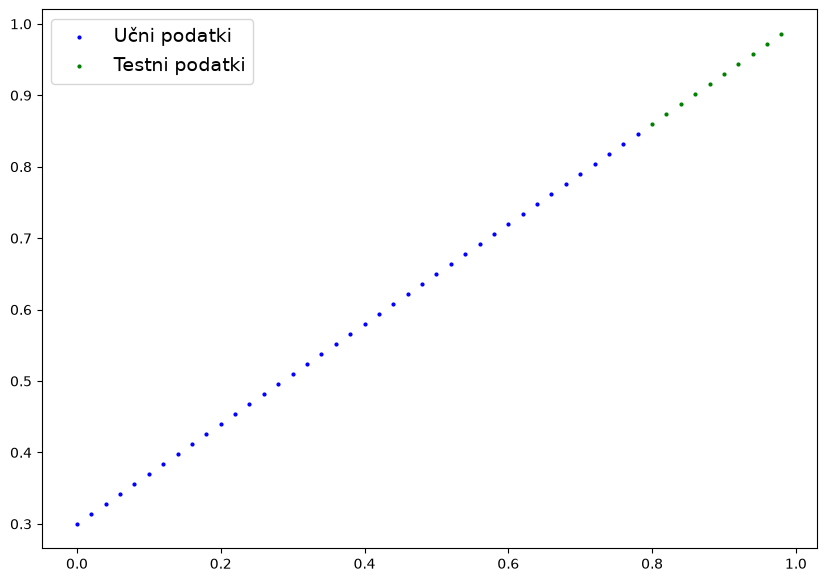

In [31]:
def izris_napovedi(train_data=X_učni_podatki,
                   train_labels=y_učni_podatki,
                   test_data=X_testni_podatki,
                   test_labels=y_testni_podatki,
                   napoved=None):

    """
    Izriše podatke za učenje, testne podatke, ter primerja napovedi
    """

    plt.figure(figsize=(10,7))

    # Izris podatkov za učenje v modrem

    plt.scatter(train_data, train_labels, c="b", s=4, label="Učni podatki")

    # Izris podatkov za testiranje v zelenem

    plt.scatter(test_data, test_labels, c="green", s=4, label= "Testni podatki")

    if napoved is not None:
        plt.scatter(test_data, napoved, c="r", s=4, label="Napoved")

    # legenda

    plt.legend(prop={"size":14})


izris_napovedi()

### Grajenje modela

Kaj model dela:

* Začne znaključnimi vrednostmi (uteži in bias)
* Pogleda naključne vrednosti in prilagodi naključne vrednosti, da bolje predstavljajo idealne vrednosti

Za to uporablja dva algoritma:

1. Gradient descent
2. Backpropagation


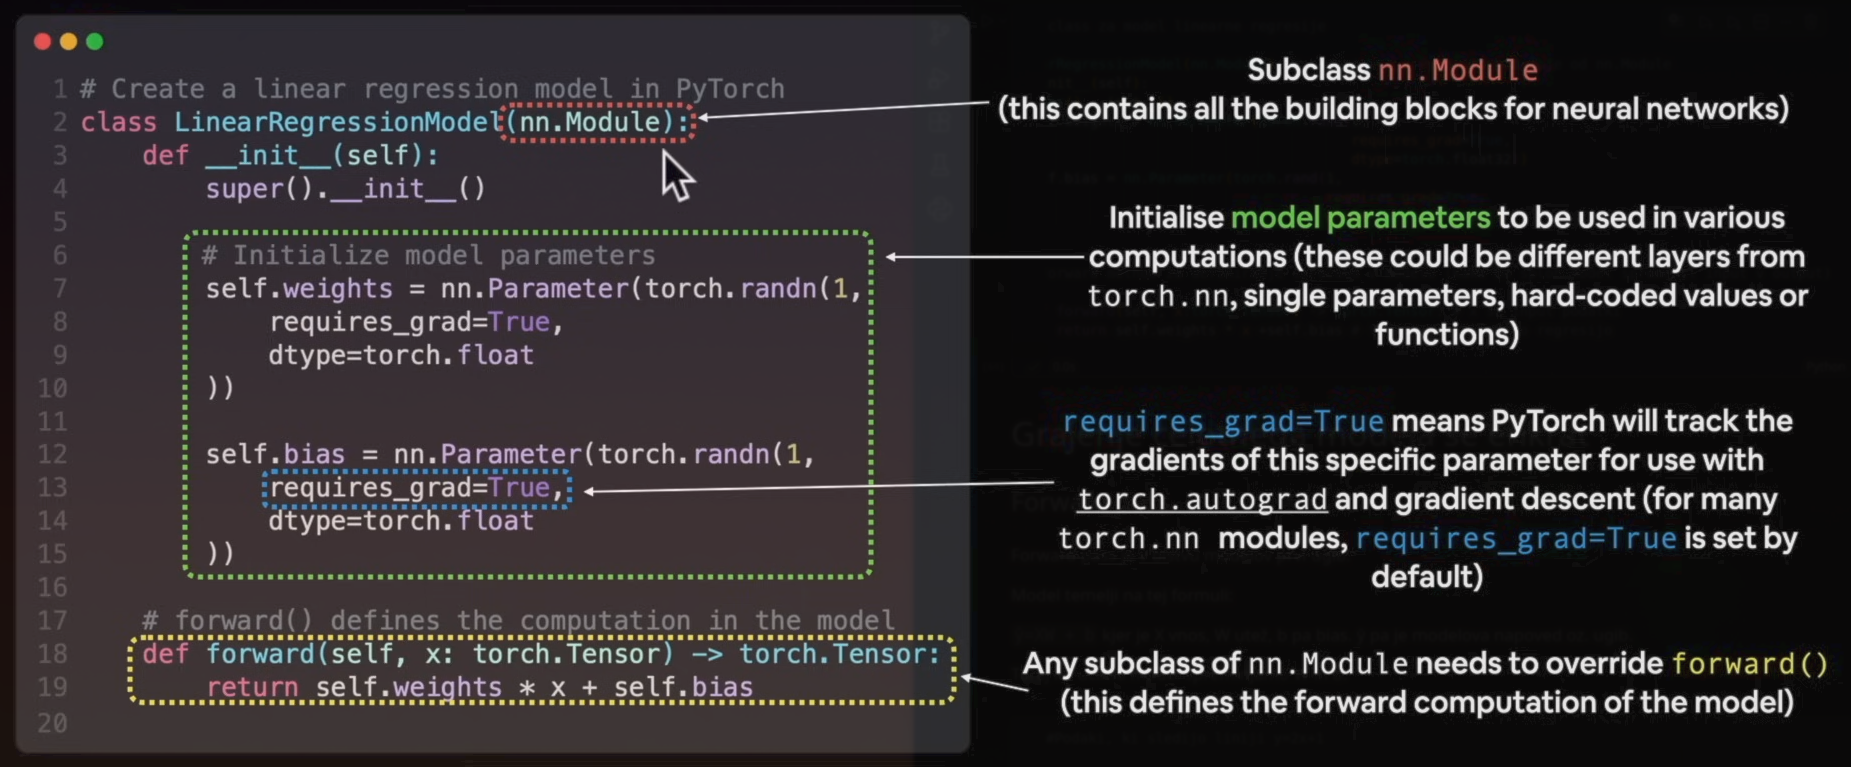

In [32]:
# Naredimo class za model linearne regresije

class LinearRegressionModel(nn.Module): # skoraj vse v Pytorchu podeduje od nn.Module
    def __init__(self):
        super().__init__()

        # Definiramo parametre

        self.weights = nn.Parameter(torch.randn(1,
                                               requires_grad=True,
                                               dtype=torch.float32))
        self.bias = nn.Parameter(torch.randn(1,
                                            requires_grad=True,
                                            dtype=torch.float32))


        # Forward method za definiranje izračuna v modelu (kako bo sploh model spremenil input v output)

    def forward(self, x:torch.Tensor) -> torch.Tensor: # x so input podatki
        return self.weights * x +self.bias # formula za linearno regresijo

### Osnove grajenja PyTorch modela

- `torch.nn`:vsebuje vse za grajenje nevronske mreže.

- `torch.nn.Parameter`: katere parametre se mora naš model naučiti (pogosto jih bo plast iz `torch.nn` nastavila za nas).

- `torch.nn.Module`:  Osnovni `class` za vse modele nevronske mreže. Če se ga subclassa, je potrebno prepisati funkcijo `forward()`

- `torch.optim`: to so optimizatorji, ki bodo pomagali z gradient descentom. 

- `forward()`: Forward funkcija se uporablja za definiranje izračuna v modelu (kako bo sploh model spremenil input v output)

CHeat sheet: https://pytorch-cn.com/tutorials/beginner/ptcheat.html

### Preverjanje vsebine modela

Vsebino in parametre modela lahko preverimo z `.parameters()` oz. `state_dict()`. 

In [33]:
# naredimo naključno seme

torch.manual_seed(42)

# Naredimo instanco modela iz prejšnje celice

model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [34]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Delanje napovedi z `torch.inference_mode()`

Poglejmo zmožnost predicije trenuthih uteži in bias z napovedjo `y_testni_podatki` na podlagi `X_testni_podatki`.

Ko podamo podatke v naš model bodo šli čez `forward()`.

Uporabili bomo `torch.inference_mode`. Izklopi sledenje gradientu.



y_prvotna_napoved : 
tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

in y_testni podatki: 
tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

 se ne ujemajo, saj uteži in bias niso bile naučene in sta trenutno tensorja z naključnimi vrednostmi


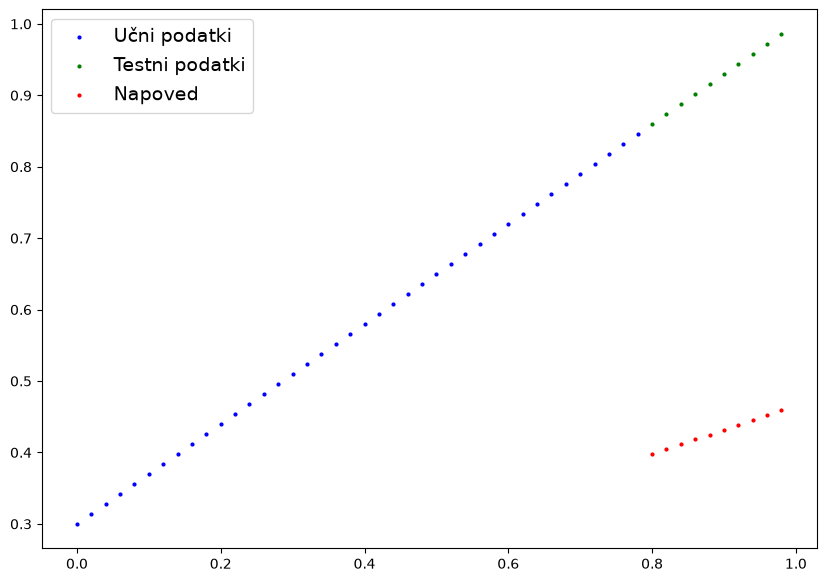

In [35]:
# napoved

with torch.inference_mode():
    y_prvotna_napoved = model_0(X_testni_podatki)

y_prvotna_napoved  # to je rezultat izračuna v forward(). Z doučenimi utežmi in biasom, bi moral ta tensor biti zelo blizu y_tesni_podatki.

print(f"y_prvotna_napoved : \n{y_prvotna_napoved }\n\nin y_testni podatki: \n{y_testni_podatki}\n\n se ne ujemajo, saj uteži in bias niso bile naučene in sta trenutno tensorja z naključnimi vrednostmi")

izris_napovedi(napoved=y_prvotna_napoved)

### Učenje modela

Cel smisel učenja modela je, da se neznane paramtere spremeni v znane oz. da bolje predstavljajo podatke.

Za merjenje napake v napovedi bomo uporabili lunkcijo `loss()` (criterion/cost).

Za učenje potrebujemo: 

- **Funkcija loss** je funkcija, ki mera kako napačna je bila napoved glede na idelni output.

- **Optimizator**: Uporabi loss za prilagajanje parametrov (uteži & bias) za izbolljšanje lossa.izris_napovedi

- Training Loop

- Testing Loop

In [36]:
# Naredimo loss

loss_fn = nn.L1Loss()  # za izračun lossa bomo uporabili povprečno absolutno napako.


# Naredimo optimizator (uporabili bomo stochastic gradient descent (obstaja še veliko drugih algoritmov npr. ADAM))

optimizator = torch.optim.SGD(params=model_0.parameters(), # parametri, ki bi jih radi optimizirali
                              lr=0.01) # learning rate (najpomebnejši hiperparameter)





### Učna zanka in testna zanka

Stvari, ki jih potrebujemo za zanko:

1. Pregledamo podatke z zanko in naredimo..

2. Forward pass (podatki grejo čez funkcijo `forward()`, da dobimo prvotno napoved)

3. Izračun lossa (primerjava resnce z napovedjo)

4. Optimizer zero grad

5. Loss backward:  premik nazaj po mreži za izračun gradienta za vsak parameter v razmerju do loss. (**Backpropagation**)

6. Optimizator: Prilagoditev parametrov za izboljšanje lossa. (**Gradient descent**)



In [37]:
# Epoha je ena zanka (hiperparameter)

epohe = 200

št_epoh = []
loss_vrednosti = []
test_loss_vrednosti = []

# 1. Zanka
for epoha in range(epohe):

    # Nastavimo model na način učenja

    model_0.train() # Da vsem parametrom (ki smo jih definirali v class) requires_grad=True

    # 2. Forward pass

    y_napoved = model_0(X_učni_podatki) # ne X_testni, ker tiste bomo uporabili za testno zanko

    # 3. Izračun lossa

    loss = loss_fn(y_napoved, y_učni_podatki)  # prmerjamo idealne podatke z napovedjo (y_učni_podatki smo nastavili samo)

    # 4. Optimizer zero grad

    optimizator.zero_grad() # resetiramo spremebo v optimizatorju

    # 5. Backpropagation na lossu v odnosu do paramterov modela

    loss.backward() # ugotovi za koliko moramo spremeniti parametre

    # 6. Gradien descent (Spremeni parametre)

    optimizator.step()  # Čez zanko se bodo spremmebe optimizatorja nabrale, tako da jih rabimo prej resetirat  (optimizator.zero_grad())


    # Testiranje

    model_0.eval() # izklopi določene nastavitve, ki niso potreben za testiranje

    with torch.inference_mode(): # izklopi sledenje gradientu in še par stvari

        # Ponovno nradimo farward pass

        testna_napoved = model_0(X_testni_podatki)

        # izračinamo loss

        test_loss= loss_fn(testna_napoved, y_testni_podatki)
        

        if epoha % 10 == 0:

            št_epoh.append(epoha)
            loss_vrednosti.append(loss)
            test_loss_vrednosti.append(test_loss)

            print(f"Epoha: {epoha} | Loss: {loss} | Test_loss: {test_loss}")







print(model_0.state_dict())



Epoha: 0 | Loss: 0.31288138031959534 | Test_loss: 0.48106518387794495
Epoha: 10 | Loss: 0.1976713240146637 | Test_loss: 0.3463551998138428
Epoha: 20 | Loss: 0.08908725529909134 | Test_loss: 0.21729660034179688
Epoha: 30 | Loss: 0.053148526698350906 | Test_loss: 0.14464017748832703
Epoha: 40 | Loss: 0.04543796554207802 | Test_loss: 0.11360953003168106
Epoha: 50 | Loss: 0.04167863354086876 | Test_loss: 0.09919948130846024
Epoha: 60 | Loss: 0.03818932920694351 | Test_loss: 0.08886633068323135
Epoha: 70 | Loss: 0.03476089984178543 | Test_loss: 0.0805937647819519
Epoha: 80 | Loss: 0.03132382780313492 | Test_loss: 0.07232122868299484
Epoha: 90 | Loss: 0.02788739837706089 | Test_loss: 0.06473556160926819
Epoha: 100 | Loss: 0.024458957836031914 | Test_loss: 0.05646304413676262
Epoha: 110 | Loss: 0.021020207554101944 | Test_loss: 0.04819049686193466
Epoha: 120 | Loss: 0.01758546568453312 | Test_loss: 0.04060482233762741
Epoha: 130 | Loss: 0.014155393466353416 | Test_loss: 0.03233227878808975
Ep

Prvotna napoved:


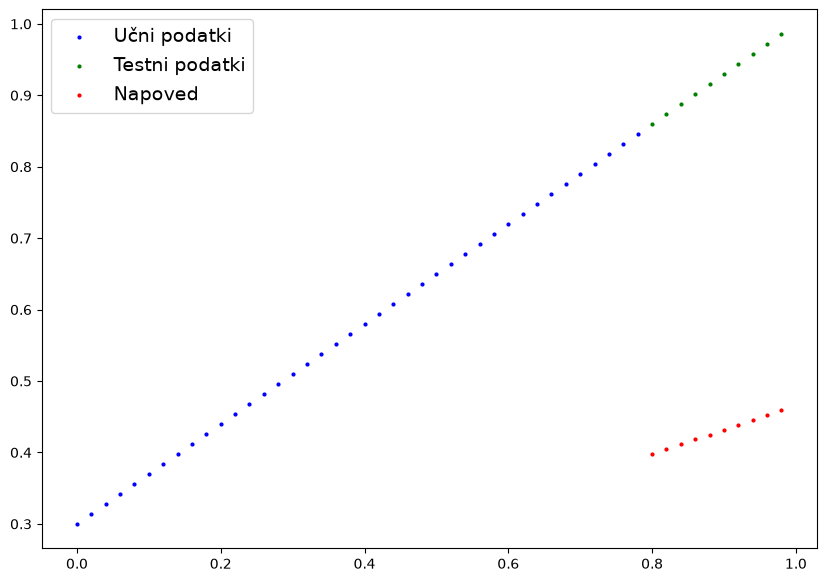

Po 200 epohah:


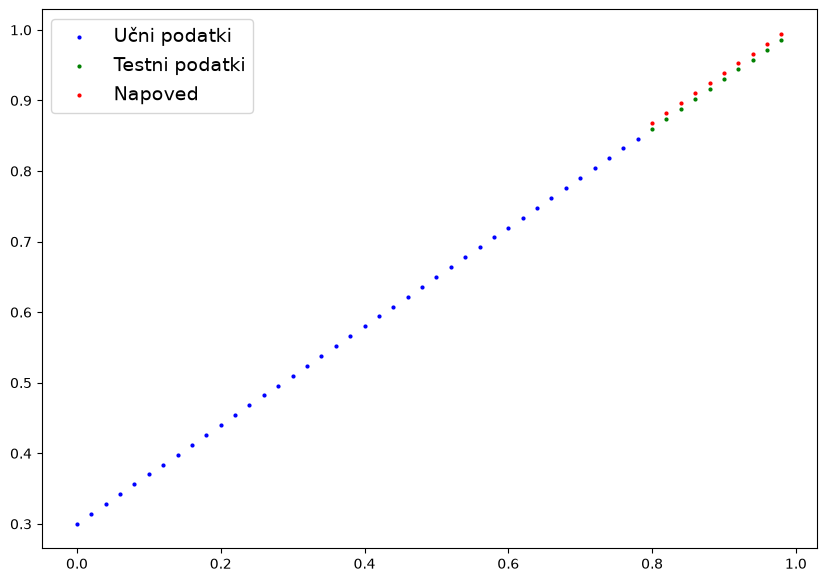

In [38]:
with torch.inference_mode():
    y_nova_napoved=model_0(X_testni_podatki)

print("Prvotna napoved:")
izris_napovedi(napoved=y_prvotna_napoved)
plt.show()
print("Po 200 epohah:")
izris_napovedi(napoved=y_nova_napoved)

/tmp/ipykernel_36168/409041080.py:1: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  plt.plot(št_epoh, np.array(torch.tensor(loss_vrednosti).cpu().numpy()), label="Loss med učenjem")


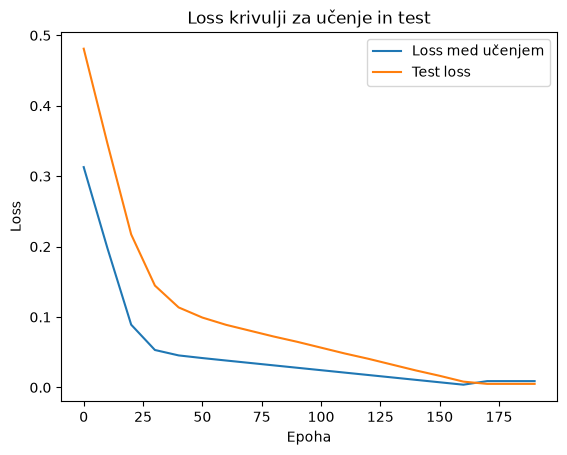

In [39]:
plt.plot(št_epoh, np.array(torch.tensor(loss_vrednosti).cpu().numpy()), label="Loss med učenjem")

plt.plot(št_epoh, np.array(torch.tensor(test_loss_vrednosti).cpu().numpy()), label="Test loss")

plt.title("Loss krivulji za učenje in test")

plt.ylabel("Loss")

plt.xlabel("Epoha")

plt.legend()

plt.show()

### Shranjevanje modela

Trije različni načini za shranjevanje in nalaganje modleov

1. `torch.save()`: shrani PyTorch objekt v pythonovem pickle formatu.

2. `torch.load()`: omogoča nalaganje shranjenge PYTorch objekta.

3. `torch.nn.Module.load_state_disct()` : omogoča nalaganje modelovega saved state dictionary `.state_dict()` (shranjeni podatki o modelu (parametri itd...))

In [40]:
# Shranjevanja modela

from pathlib import Path

# Naredimo direktorij za modele

MODEL_PATH = Path("modeli")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Model save path

MODEL_IME = "01_pytorch_workflow osnove.pth"

MODEL_SAVE_PATH = MODEL_PATH / MODEL_IME

# 3. Shranimo modelov state dict

print(f" Shranjujem model v: {MODEL_SAVE_PATH}")

torch.save(obj=model_0.state_dict(), 
           f=(MODEL_SAVE_PATH))


 Shranjujem model v: modeli/01_pytorch_workflow osnove.pth


### Nalaganje modela

 Ker smo shranili zgolj modelov `state_dict()` (ne celotnega modela), bomo naredili novo instanco modela in naložili shranjen `state_dict()` prvotnega modela.



In [41]:
# NAredimo novo instanoc modela

naložen_model_0 = LinearRegressionModel()

# Naložimo state_dict prvotnega modela direktno v nov model
naložen_model_0.load_state_dict(torch.load(f="modeli/01_pytorch_workflow osnove.pth"))

<All keys matched successfully>

In [42]:
# Paramteri modelov se zdaj ujemajo

print(model_0.state_dict())
print(naložen_model_0.state_dict())

OrderedDict({'weights': tensor([0.6990]), 'bias': tensor([0.3093])})
OrderedDict({'weights': tensor([0.6990]), 'bias': tensor([0.3093])})


In [43]:
# Naredimo napoved z naloženim modelom

naložen_model_0.eval()

with torch.inference_mode():

    naložen_model_0_napovedi = naložen_model_0(X_testni_podatki)

print(naložen_model_0_napovedi == testna_napoved)

print("\nTestne napovedi obeh modelov se ujemajo!!!")

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

Testne napovedi obeh modelov se ujemajo!!!


In [44]:
X_testni_podatki, naložen_model_0_napovedi

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8685],
         [0.8825],
         [0.8965],
         [0.9105],
         [0.9245],
         [0.9384],
         [0.9524],
         [0.9664],
         [0.9804],
         [0.9944]]))

## Še enkrat model v celoti



In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt


# Najprej poskusimo uporabiti GPU

device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Device: {device}")

Device: cpu


### Podatki

In [ ]:
# Naredimo podatke z formulo za linearno regresijo (y = utež * X + bias)

utež = 0.7
bias = 0.3

# Podatki

start = 0
end = 1
step = 0.02

# X in y (značilnosti in labele)

X = torch.arange(start=start, step=step, end=end).unsqueeze(dim=1)

y = utež * X + bias

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])

In [68]:
# deljnje podatkov

delitev = int(0.8 * len(X))
X_učni_podatki, y_učni_podatki = X[:delitev],y[:delitev]
X_test, y_test = X[delitev:], y[delitev:]
len(X_učni_podatki), len(X_test)

(40, 10)

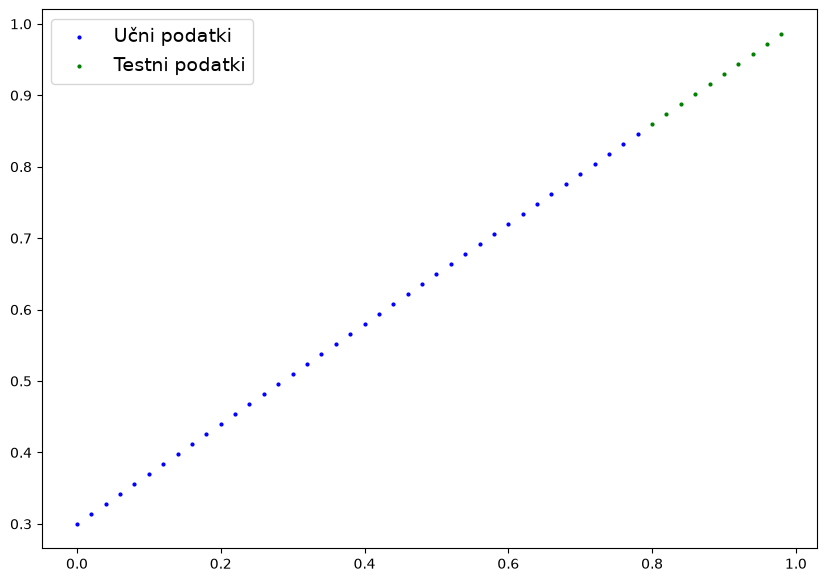

In [ ]:
# izris podatkov
# funkcijo smo si sposodili iz prejšnjega primera
izris_napovedi(X_učni_podatki, y_učni_podatki)


### Naredimo model

In [73]:
# Naredimo linearni model s tem, da bomo subclassal nn.Model

class LinearRegressionModelV2(nn.Module):

    def __init__(self):
        super().__init__()

    # uporabimo nn.Linear(), da naredimo parametre. (V prejšnjem primeru smo parametre postavili sami)

        # in_feaures = 1, out_features = 1 pomeni, da za vsak x hočemo dobiti en y. Torej en x je en y. V bolj kompleksnih primerih bi lahko imeli več in featurjev, ki bi dajali rezultat (output)
        # to abtracta ročno deklerirane uteži in bias
        #zato lahko krajše definiramo forward, saj je formula za linearno regresijo avtomatsko vnešena

        self.linar_layer = nn.Linear(in_features=1,
                                 out_features=1)


    def forward(self, x:torch.tensor):
        return self.linar_layer(x)


# Naredimo naključno seme

torch.manual_seed(42)

model_1 = LinearRegressionModelV2()

model_1.state_dict()


OrderedDict([('linar_layer.weight', tensor([[0.7645]])),
             ('linar_layer.bias', tensor([0.8300]))])

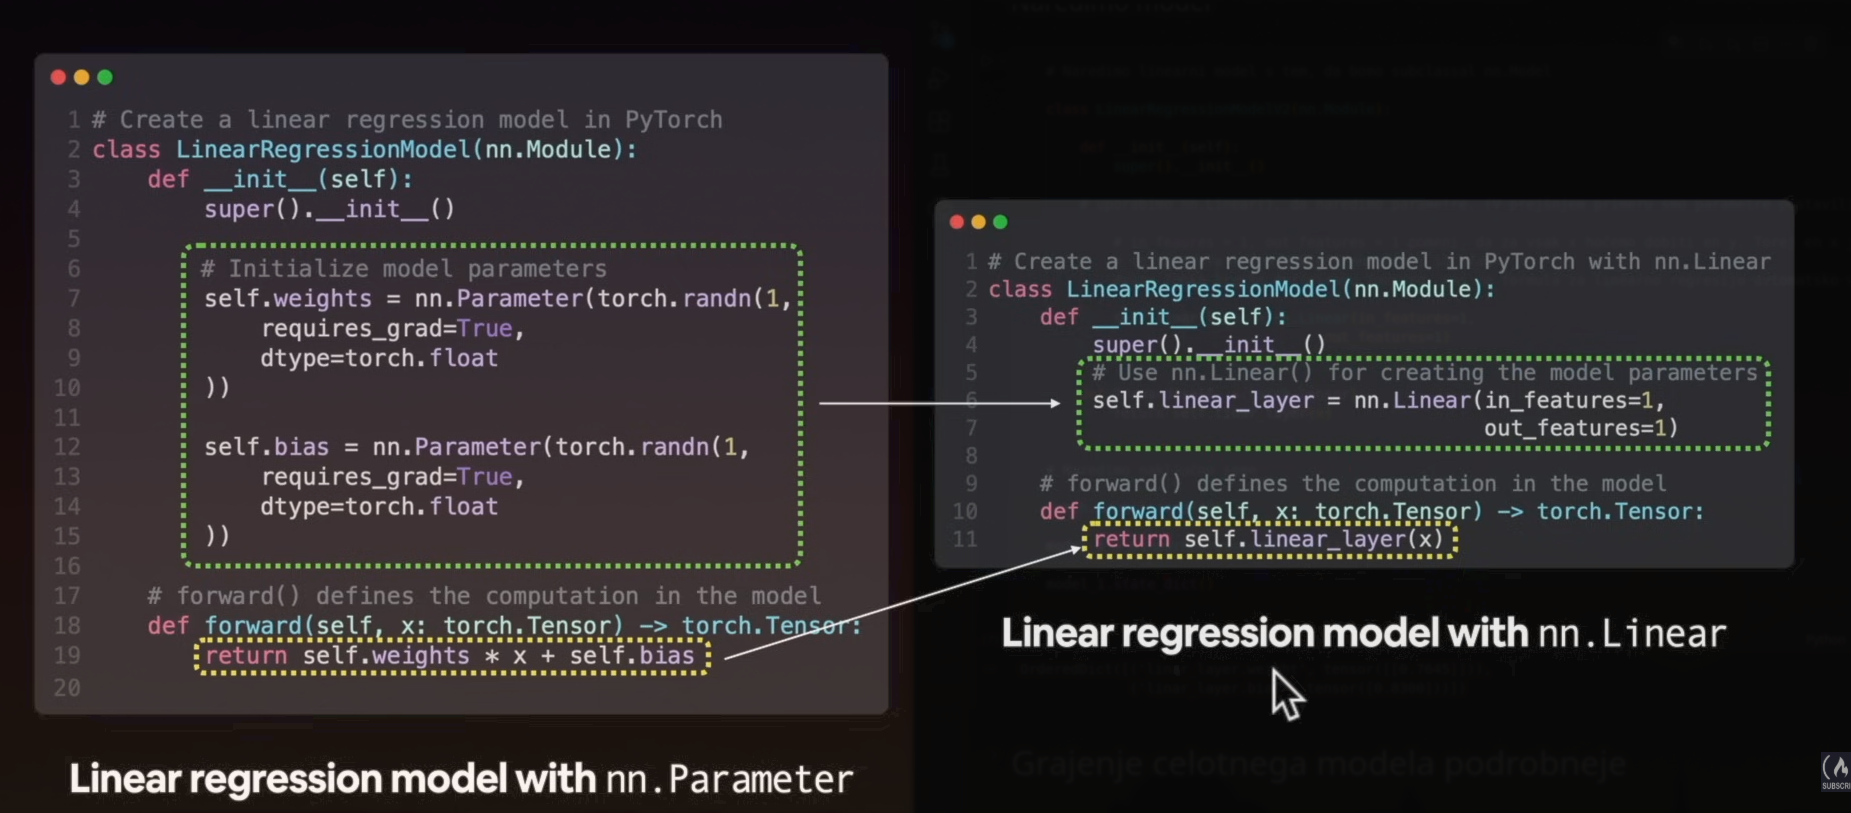

In [79]:
# Na kateri napravi je model
print(f"Model je na {next(model_1.parameters()).device}")

# Nastavimo model da uporablja željeno napravo

model_1.to(device)
print(f"Model je na {next(model_1.parameters()).device}")

Model je na cpu
Model je na cpu


### Učenje

Potrebujemo:

- Funkcijo loss
- Optimizator
- Učno zanko 
- Testno zanko



In [81]:
loss_fn = nn.L1Loss() # Mean Absolute Error

optimizator = torch.optim.SGD(lr=0.01,
                              params=model_1.parameters())


# Učna zanka

torch.manual_seed(42)

epohe = 200

# Podatke moramo dati na željeno napravo

X_učni_podatki = X_učni_podatki.to(device)
X_test = X_test.to(device)
y_učni_podatki = y_učni_podatki.to(device)
y_test = y_test.to(device)

for epoha in range(epohe):

    model_1.train()

    # Forward pass
    y_napoved=model_1(X_učni_podatki)

    # Loss
    loss = loss_fn(y_napoved, y_učni_podatki)

    # Optimizator zero grad
    optimizator.zero_grad()

    # Backpropagation
    loss.backward()

    # Optimizator

    optimizator.step()

    # Testiranje

    model_1.eval()

    with torch.inference_mode():

        test_napoved = model_1(X_test)

        test_loss = loss_fn(test_napoved, y_test)

    if epoha % 10 == 0:
        print(f" Epoha: {epoha} | Loss: {loss} | Test loss: {test_loss}")
        






 Epoha: 0 | Loss: 0.5551779866218567 | Test loss: 0.5739762187004089
 Epoha: 10 | Loss: 0.4399680495262146 | Test loss: 0.4392663538455963
 Epoha: 20 | Loss: 0.3247582018375397 | Test loss: 0.30455657839775085
 Epoha: 30 | Loss: 0.20954827964305878 | Test loss: 0.16984674334526062
 Epoha: 40 | Loss: 0.09433844685554504 | Test loss: 0.03513689711689949
 Epoha: 50 | Loss: 0.023886386305093765 | Test loss: 0.04784906655550003
 Epoha: 60 | Loss: 0.0199567973613739 | Test loss: 0.04580312222242355
 Epoha: 70 | Loss: 0.016517987474799156 | Test loss: 0.0375305712223053
 Epoha: 80 | Loss: 0.013089170679450035 | Test loss: 0.029944902285933495
 Epoha: 90 | Loss: 0.009653178043663502 | Test loss: 0.02167237363755703
 Epoha: 100 | Loss: 0.006215679459273815 | Test loss: 0.014086711220443249
 Epoha: 110 | Loss: 0.002787243574857712 | Test loss: 0.005814164876937866
 Epoha: 120 | Loss: 0.0012645035749301314 | Test loss: 0.013801807537674904
 Epoha: 130 | Loss: 0.0012645035749301314 | Test loss: 0.

### Napoved in ocena napovedi

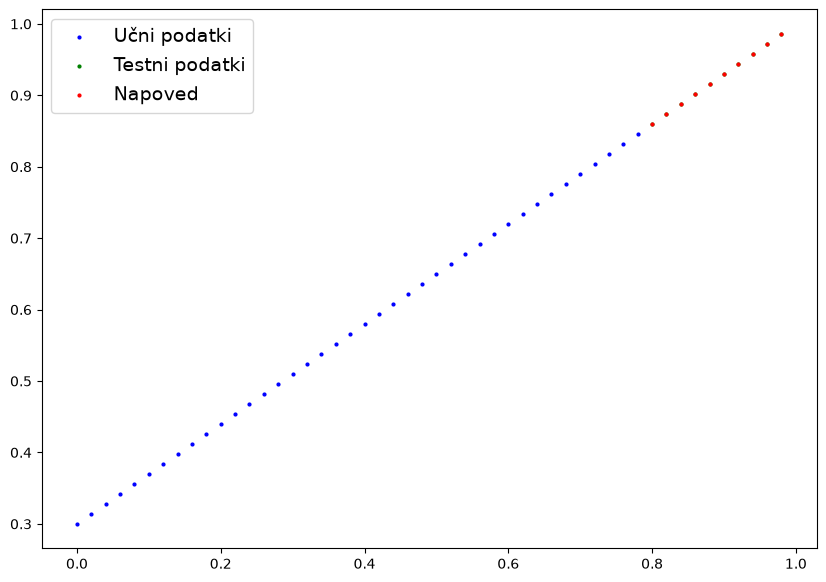

In [95]:

# vklopimo evaluation model

model_1.eval()

# naredimo napoved na testnih podatkih

with torch.inference_mode():
    y_napoved = model_1(X_test)


izris_napovedi(train_data=(X_učni_podatki).numpy(), 
               train_labels=(y_učni_podatki).numpy(),
               test_data=(X_test).numpy(), 
               test_labels=(y_test).numpy(),  
               napoved=(y_napoved).numpy())

In [82]:
model_1.state_dict()

OrderedDict([('linar_layer.weight', tensor([[0.6968]])),
             ('linar_layer.bias', tensor([0.3025]))])

### Shranjevanje in nalaganje modela 



In [102]:
# Naredimo directory

MODEL_PATH = Path("modeli")

MODEL_PATH.mkdir(parents=True, exist_ok=True)

# naredimo save path

IME_MODELA = "model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / IME_MODELA

# shranimo modelov state dict

print(f"Shranjujem model: {MODEL_SAVE_PATH}")

torch.save(obj=model_1.state_dict(),
           f=MODEL_SAVE_PATH)



# Naložimo model

# naredimo novo instaco modela
naloženi_model_1 = LinearRegressionModelV2()

# Naložimo state_dict prejšnega modela

naloženi_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

# prenesemo model na željeno napravo

naloženi_model_1.to(device)

naloženi_model_1.state_dict()

Shranjujem model: modeli/model_1.pth


OrderedDict([('linar_layer.weight', tensor([[0.6968]])),
             ('linar_layer.bias', tensor([0.3025]))])

In [103]:
# Evaluiramo naloženi model

naloženi_model_1.eval()

with torch.inference_mode():
    naloženi_model_1_napovedi = naloženi_model_1(X_test)


naloženi_model_1_napovedi == y_napoved

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## Grajenje celotnega modela podrobneje 

### Forward pass
 
Forward pass je v bistvu modelov prvi ugib.

Model temelji na tej formuli: 

`ŷ=XW + b` kjer je X vnos, W utež, b pa bias. ŷ pa je modelova napoved oz. ugib.

Torej ko učimo model spreminjamo W in b.

In [45]:
#Podaki, ki sledijo liniji y=2x+1

N = 10 # naši podatki imajo 10 datapointov


# vsak data point ima en input feature in 1 output value

D_in=1 
D_out=1

#Input podatki

X=torch.randn(N, D_in)

print(X)
print()

# Naredimo pravilne target lable y z pravim W in pravim b
#Pravi W je 2.0 in pravi b je 1

praviln_W=torch.tensor([[2.0]])

praviln_b = torch.tensor(1.0)

# resnica
praviln_Y= X @ praviln_W +praviln_b +torch.randn(N, D_out) * 0.1  # 0.1 je za noise

print(praviln_Y)
print()

# Nraedimo začetne uteži in bias
W = torch.randn(D_in, D_out, requires_grad=True)
b = torch.randn(1, requires_grad=True)

print(f"Začetne uteži W: \n{W}\n")  # To je modelov prvotni ugib, ki je popolnoma napačen
print(f"Začetni bias b: \n{b}")

tensor([[-1.1229],
        [-0.1863],
        [ 2.2082],
        [-0.6380],
        [ 0.4617],
        [ 0.2674],
        [ 0.5349],
        [ 0.8094],
        [ 1.1103],
        [-1.6898]])

tensor([[-1.3446],
        [ 0.7231],
        [ 5.5486],
        [-0.1943],
        [ 1.8467],
        [ 1.4596],
        [ 2.2051],
        [ 2.6873],
        [ 3.1878],
        [-2.3001]])

Začetne uteži W: 
tensor([[0.2815]], requires_grad=True)

Začetni bias b: 
tensor([0.0562], requires_grad=True)


Formulo y=XW+b uporabimo v kodi:

`y_hat= X @ W +b`

In [46]:

y_hat= X @ W +b

print(f"Predikcija y_hat (prve tri vrstice): \n{y_hat[:3]}\n")
print(f"Pravilni label praviln_y (prve tri vrstice): \n{praviln_Y[:3]}")


Predikcija y_hat (prve tri vrstice): 
tensor([[-0.2599],
        [ 0.0037],
        [ 0.6778]], grad_fn=<SliceBackward0>)

Pravilni label praviln_y (prve tri vrstice): 
tensor([[-1.3446],
        [ 0.7231],
        [ 5.5486]])


Rezultati y_hat se niti malo ne ujemajo z resnico (pravilni_Y).

### Backward pass

Ugotoviti kako napačen je bil forward pass ugib. To bomo ugotovili z loss.
Loss bomo ugotovili z mean squared error (MSE).

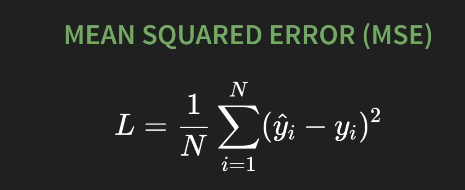

To pomeni, da bomo za vsako napoved:

1. `(y_hat - praviln_Y)`
2. nato bomo dobljeno dali na kvadrat, da dobimo pozitivno številko
3. Na koncu pa bomo izračunali povprečje teh vrednosti

V kodi to pomeni:

In [47]:
napaka=y_hat - praviln_Y
napaka_na_kvadrat= napaka ** 2

loss=napaka_na_kvadrat.mean()

print(f"Loss: {loss}")

Loss: 5.119847297668457


Zdaja rabimo ugotoviti za koliko spremeniti W in b da zmanjšamo loss. To bomo naredili z autogradom in sicer gradient lossa v odnosu do W (uteži) in gradient lossa v odnosu do b (biasa).

To bomo naredili z `loss.backward()` (tu pridejo v poštev vse vrednosti, ki imajo`requires_grad=True`)

In [48]:
loss.backward()

print(f"Gradient za W: \n{W.grad}\n")
print(f"Gradient za b: \n{b.grad}\n")

Gradient za W: 
tensor([[-4.4657]])

Gradient za b: 
tensor([-2.5527])



Negativen `.W.grad` pomeni pomeni, da če bomo povečali W, se bo loss zmanjšal

`.grad()` nam pove za koliko rabimo spremeniti W in b.

To ponovimo, dokler nismo zadovoljni z rezultatom. Temu se reče  **training loop** pri katerem se upošteva **gradient descent** .

### Algoritem gradient descent

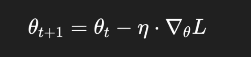

- Θ predstavlja vse parametre. V našem primeru W in b.

- η stopnja učenja. Ponavadi majhna številja (0.01), kki določa, kako velik korak naredimo pri vsaki posodobitvi parametrov.

- {\displaystyle \nabla } *L* predstavlja gradient lossa. Kar smo izračunali v prejšnem koraku (W.grad in b.grad)

v kodi to pomeni:

`nov_W = star_W - learning_rate * W.grad`

`nov_b = star_b - learning_rate * b.grad`

To ponavljamo čez več epoh. Ena epoha je en training loop.

### Training loop

Pomembni sta dve funkciji:

- `torch.no_grad()` ki sporoča torchu, da naj ne spremlja sprememb parametrov, saj jih bomo spreminjali ročno

- `.grad.zero_()` ki sporoča, da je potrebno resetirat gradiente po vsaki epohi. 

In [49]:
#hiperparametri

learning_rate, epohe= 0.01, 1000

#ponovno definiramo parametre (začeten ugib)
W, b =torch.randn(1,1, requires_grad=True), torch.randn(1, requires_grad=True)

#Training loop

for epoha in range(epohe):

    #forwardpass in loss
    y_hat = X @ W + b
    loss = torch.mean((y_hat-praviln_Y)**2)

    # backward pass
    loss.backward()

    #Update parametrov
    with torch.no_grad():
        W-=learning_rate * W.grad; b -= learning_rate * b.grad

    #resetiramo gradiente
    W.grad.zero_(); b.grad.zero_()


    # prikaz učenja modela
    if epoha % 10 == 0:
        print(f"Epoha {epoha:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")


print(f"\nFinalni paramteri: W={W.item():.3f}, b={b.item():.3f}") 

print("Pravi parametri W=2.000, b=1.000")

Epoha 00: Loss=4.9256, W=0.563, b=-0.208
Epoha 10: Loss=2.9282, W=0.908, b=0.060
Epoha 20: Loss=1.7430, W=1.173, b=0.268
Epoha 30: Loss=1.0394, W=1.374, b=0.431


Epoha 40: Loss=0.6215, W=1.528, b=0.558
Epoha 50: Loss=0.3731, W=1.646, b=0.658
Epoha 60: Loss=0.2254, W=1.736, b=0.736
Epoha 70: Loss=0.1375, W=1.804, b=0.798
Epoha 80: Loss=0.0851, W=1.856, b=0.846
Epoha 90: Loss=0.0539, W=1.895, b=0.884
Epoha 100: Loss=0.0352, W=1.925, b=0.914
Epoha 110: Loss=0.0241, W=1.948, b=0.937
Epoha 120: Loss=0.0174, W=1.965, b=0.956
Epoha 130: Loss=0.0134, W=1.978, b=0.970
Epoha 140: Loss=0.0110, W=1.987, b=0.982
Epoha 150: Loss=0.0095, W=1.995, b=0.991
Epoha 160: Loss=0.0086, W=2.000, b=0.999
Epoha 170: Loss=0.0081, W=2.004, b=1.004
Epoha 180: Loss=0.0078, W=2.007, b=1.009
Epoha 190: Loss=0.0076, W=2.010, b=1.013
Epoha 200: Loss=0.0075, W=2.011, b=1.016
Epoha 210: Loss=0.0074, W=2.013, b=1.018
Epoha 220: Loss=0.0073, W=2.014, b=1.020
Epoha 230: Loss=0.0073, W=2.014, b=1.022
Epoha 240: Loss=0.0073, W=2.015, b=1.023
Epoha 250: Loss=0.0073, W=2.015, b=1.024
Epoha 260: Loss=0.0073, W=2.015, b=1.025
Epoha 270: Loss=0.0073, W=2.015, b=1.025
Epoha 280: Loss=0.0073

Loss se je zmanjševal W in b pa sta postajala čedalje bližje pravima W in b.

## Modul torch.nn

Modul za gradnjo nevronskih mrež. Vsebuje vse gradnike, ki so potrebovane: plasti, aktivacijske funkcije, funkcije izgube in osnovni razred za svoje modele.

Najpomembnejša funkcija je:

- `torch.nn.Linear`: je zakar smo v prešnjem modelu uporabljali `X @ W + b`. Zapakira W in b v objekt.


In [50]:
# Input ima en feature, output pa eno vrednost

D_in=1
D_out=1

# Naredimo linarni sloj

linear_layer = torch.nn.Linear(in_features=D_in, out_features=D_out)

print(f"Linerne uteži (W): {linear_layer.weight}\n")

print(f"Linerne bias (b): {linear_layer.bias}\n")

# Uporablja se kot funkcijo. To je forward pass (prvi ugib)
# X je tensor [10, 1] iz prejšnjega poglavja

y_hat_nn = linear_layer(X)

print(f"Output nn.Liner (prve tri vrstice); \n{y_hat_nn[:3]}")

Linerne uteži (W): Parameter containing:
tensor([[0.3163]], requires_grad=True)

Linerne bias (b): Parameter containing:
tensor([-0.0174], requires_grad=True)

Output nn.Liner (prve tri vrstice); 
tensor([[-0.3725],
        [-0.0763],
        [ 0.6810]], grad_fn=<SliceBackward0>)


Lahko vidimo da funkcija sama naredi uteži in bias ter da `requires_grad=True`

Torej **Parameter** je tensor, ki ima:
- `requires_grad=True`
- se sam naredi ob stavritvi modela
- sledi spremembam

Imajo pa slabost, da lahko prepoznajo samo premico. Torej ne delujejo z zahtevnimi inputi. 

Zato potrebujemo **aktivacijsko funkcijo**, ki vnese v mrežo nelinaernost.

### `nn.ReLu`

Rectefied linear unit. Deluje po principu, če je input negativen, ga naredi 0. 

In [51]:
relu = torch.nn.ReLU()
testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = relu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")

Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])


### `nn.GELU`

Gaussian error linear unit. Gladkejša verzija ReLu. Se uporablja v modernih transformerjih.

In [52]:
gelu = torch.nn.GELU()

testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = gelu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")


Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([-0.0455, -0.1543,  0.0000,  0.3457,  1.9545])


### `nn.Softmax`

Uporablja se za zadnjo plast pri klasifikaciji. Konverta surove napovedi modela (logits) v distribucijo verjetnosti. Vrednosti bodo med 0 in 1, ter njihova vsota bo 1.

In [53]:
softmax= torch.nn.Softmax(dim=1)

# surove napovedi modelov za dva predmeta, čez 4 možne razrede

logits= torch.tensor([[1.0, 3.0, 0.5, 1.5], [-1.0, 2.0, 1.0, 0.0]])

verjetnosti=softmax(logits)

print(f"Verjetnosti outputa: \n{verjetnosti}\n")
print(f"Vsota verjetnosti za prvi predmet: {verjetnosti[0].sum()}")

Verjetnosti outputa: 
tensor([[0.0939, 0.6942, 0.0570, 0.1549],
        [0.0321, 0.6439, 0.2369, 0.0871]])

Vsota verjetnosti za prvi predmet: 1.0


### `nn.Embedding`

Spremeni besede v številke. Vsaka beseda dobi svoj unikaten vektor.
 

In [54]:
vocab_size = 10 # Naš jezik ima 10 unikatnih besed
embedding_dim = 3 # Vsaka beseda bo predstavljena kot 3D vector


# Naredi matriko uteži določene oblike, z naključnimi številkami 
embedding_layer = torch.nn.Embedding(vocab_size, embedding_dim) 

# input je stavek, kjer je vsaka beseda ID. Npr. 1, 5, 0, 8

input_ids = torch.tensor([[1, 5, 0, 8]])

besedni_vektorji= embedding_layer(input_ids)

print(f"Input token (oblike [1,4]): \n{input_ids}\n")
print(f"Izhodni vektroji besed (oblike [1,4,3]): \n{besedni_vektorji}")

Input token (oblike [1,4]): 
tensor([[1, 5, 0, 8]])

Izhodni vektroji besed (oblike [1,4,3]): 
tensor([[[ 0.1754,  1.3852, -0.4459],
         [-0.7106, -0.6021,  0.9604],
         [ 1.8113,  0.1606,  0.3672],
         [ 1.2243,  0.0981,  1.7423]]], grad_fn=<EmbeddingBackward0>)


### `nn.Layernorm`

Preprečuje izginotje vrednosti, saj jih preračuna v stabilen obsag. Na nek način normalizira vrednosti v tensorju

In [55]:
# Besedni vektorji imajo dimenzijo 3

norm_layer = torch.nn.LayerNorm(normalized_shape=3)
input_features = torch.tensor([[[1.0, 2.0, 3.0],[4.0, 5.0, 6.0]]])
normalizirani_featurji = norm_layer(input_features)

print(f"input_features: \n{input_features}\n")
print(f"normalizirani_featurji: \n{normalizirani_featurji}\n")
print(f"Povprečje (moralo bi biti okoli 0): \n{normalizirani_featurji.mean(dim=-1)}")

input_features: 
tensor([[[1., 2., 3.],
         [4., 5., 6.]]])

normalizirani_featurji: 
tensor([[[-1.2247,  0.0000,  1.2247],
         [-1.2247,  0.0000,  1.2247]]], grad_fn=<NativeLayerNormBackward0>)

Povprečje (moralo bi biti okoli 0): 
tensor([[0., 0.]], grad_fn=<MeanBackward1>)


### `nn.Dropout`

Preprečuje prenaučenost modela, s tam da naključno spremeni nekatere nevrona na 0, ter s tam zmanjša zanašanje modela na posamezne nevrone. Dekuje samo med učenjem.


In [56]:
dropout_layer = torch.nn.Dropout(p=0.5)
input_tensor = torch.ones(1, 10)

# Aktivacija dropouta za učenje
dropout_layer.train()
output_med_učenjem = dropout_layer(input_tensor)

# deaktiviramo dropout za evaluacijo 
dropout_layer.eval()
output_med_evaluacijo = dropout_layer(input_tensor)

print(f"Input: \n{input_tensor}\n")
print(f"Output med učenjem (naključne vrednosti spremenjene v 0 ostale pa skalirane): \n{output_med_učenjem}\n")
print(f"Output med evaluacijo (brez spremembe): \n{output_med_evaluacijo}\n")


Input: 
tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

Output med učenjem (naključne vrednosti spremenjene v 0 ostale pa skalirane): 
tensor([[2., 0., 2., 0., 2., 2., 0., 2., 2., 0.]])

Output med evaluacijo (brez spremembe): 
tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])



## `nn.Module` in `torch.optim`

### `nn.Module`

Je osnovni razred za vse nevronske mreže in njihove dele (plasti, bloke, cele modele). Naredi tri stvari:
 
- Hrani parametre. Vse, kar je nn.Parameter (uteži, pristranskosti), se samodejno registrira in je dostopno prek model.parameters().

- Definira računanje v metodi forward(). Model pokličeš kot funkcijo (model(x)), PyTorch pa v ozadju pokliče forward.

- Gnezdi se. Modul lahko vsebuje druge module, kar omogoča sestavljanje zapletenih arhitektur iz preprostih blokov.

Poleg tega skrbi za state_dict() (shranjevanje/nalaganje uteži), .to(device) (premik na GPU), .train() / .eval() (preklop načina za dropout, batchnorm).

### `torch.optim`

Ta modul vsebuje optimizatorje (SGD, Adam, AdamW, RMSprop ...). Optimizator ne ve nič o arhitekturi: dobi seznam parametrov in njihove gradiente ter jih po določenem pravilu posodobi.



## Ponovno grajenje modela

In [57]:
import torch.nn as nn


# podedujemo od nn,Module

class LinearRegressionModel(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        # v konstruktortju definiramo plasti, ki jih bomo uporabili
        self.linear_layer= nn.Linear(in_features, out_features)

    def forward(self, x):
        # V forward pasuu (prvi ugib) povežemo plasti
        return self.linear_layer(x)


# ustvarimo model

model= LinearRegressionModel(in_features=1, out_features=1)

print("Arhitektura modela: ")
print(model)




Arhitektura modela: 
LinearRegressionModel(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)


In [58]:
import torch.optim as optim 

# hiperparametri 
learning_rate = 0.1

# NAredimo Adam optimizator.
# Nato mu damo model.paramteres(), da mu povemo katere tensorje naj upravlja

optimizer= optim.Adam(model.parameters(), lr=learning_rate)

# dodamo še v naprej narejeno funkcijo za loss

loss_fn = nn.MSELoss() # Povprečena kvadratna napaka za loss

### Training loop: 

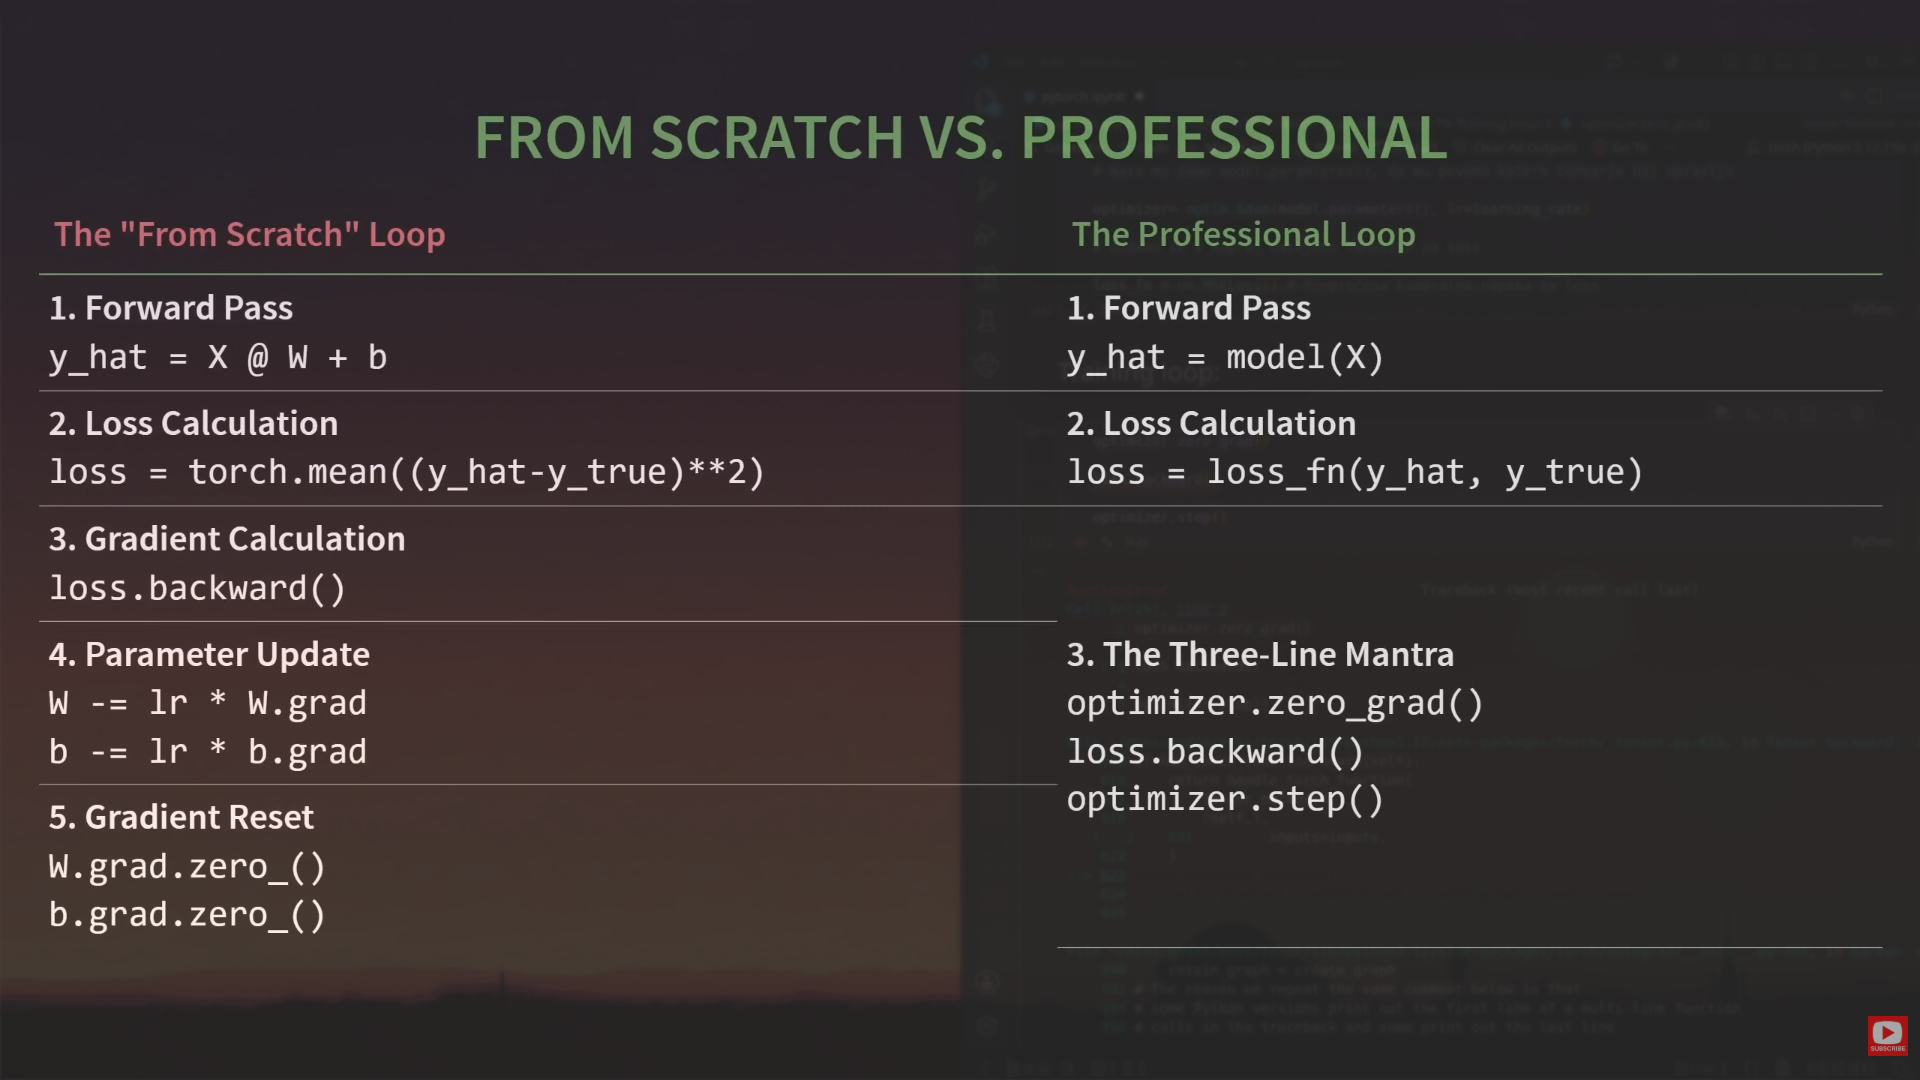

In [59]:

epohe= 100

for epoha in range(epohe):

    # FORWARD PASS
    y_hat=model(X)

    # Izračun lossa

    loss= loss_fn(y_hat, praviln_Y)

    # izničit gradiente
    optimizer.zero_grad()

    # Izračun gradientov
    loss.backward()

    # Posodobitev parametrov
    optimizer.step()


    # Napredek
    if epoha % 10 == 0:
        print(f"Epoha {epoha: 02d}: Loss={loss.item():.4f}")



Epoha  0: Loss=12.8153
Epoha  10: Loss=4.3208
Epoha  20: Loss=0.8488
Epoha  30: Loss=0.2052
Epoha  40: Loss=0.0999
Epoha  50: Loss=0.0347
Epoha  60: Loss=0.0274
Epoha  70: Loss=0.0140
Epoha  80: Loss=0.0073
Epoha  90: Loss=0.0082


viri:

0. https://docs.pytorch.org/docs/2.14/index.html
1. https://www.youtube.com/watch?v=r1bquDz5GGA&t=329s
2. https://www.youtube.com/watch?v=V_xro1bcAuA&t=2640s
3. https://www.youtube.com/watch?v=woSNI-aejnU